# Implemntereting af single layer perceptron

## 1. Import af bibliotek

Matplotlib bruges til at visualisere træningsdataene og modellens beslutningsgrænse.

In [87]:
import matplotlib.pyplot as plt

## 2. Oprettelse af Perceptron-klassen

Klassen indeholder modellens vægte, bias og læringsrate. Den indeholder også metoder til aktivering, forudsigelse og træning.

In [88]:
# Opret Perceptron som en klasse der har værdierne vægt, bias og læringsrate

class Perceptron:
    def __init__(self, antal_inputs):
        # Der skal være en vægt for hvert input.
        # Nulstart gør modellen neutral, før den er blevet trænet.
        self.vægt = [0] * antal_inputs
        # Bias flytter beslutningsgrænsen uafhængigt af inputværdierne.
        self.bias = 0
        # En lille læringsrate giver mindre vægtjusteringer ad gangen.
        self.læringsrate = 0.001


    def aktiveringsfunktion(self, værdi):
        # aktiveringsfunktionen ReLU
        if værdi < 0:
            return 0
        else:
            return værdi


    def forudsig(self, inputs):
        # Start med bias, og læg hvert input ganget med sin vægt til.
        samlet_værdi = self.bias

        for i in range(len(inputs)):
            samlet_værdi += inputs[i] * self.vægt[i]
        return self.aktiveringsfunktion(samlet_værdi)

    def klassificer(self, inputs):
        return int(self.forudsig(inputs) >= 0.5)

    def træn(self, træningsdata, antal_epoker):
        # En epoke betyder, at modellen gennemgår hele datasættet én gang.
        for epoke in range(antal_epoker):
            for inputs, forventet in træningsdata:
                forudsigelse = self.forudsig(inputs)
                # Fejlen viser, om forudsigelsen skal op eller ned.
                fejl = forventet - forudsigelse

                # Vægtene justeres i retning af det korrekte svar.
                # Inputtet bestemmer, hvilke vægte der påvirkes.
                for i in range(len(self.vægt)):
                    self.vægt[i] += self.læringsrate * fejl * inputs[i]
                # Bias justeres også, så beslutningsgrænsen kan flyttes.
                self.bias += self.læringsrate * fejl

## 3. OR-træningsdata

Hvert eksempel består af inputværdierne og det korrekte svar. OR-logik giver 1, hvis mindst ét af de to input er 1.

In [119]:
import random

def generate_rows(num_rows):
    rows = []
    forventetErEn = 0

    for _ in range(num_rows):
        digits = [random.uniform(0.0, 1.0) for _ in range(2)]
        expected = int(sum(digits) >= 1.0)

        if expected == 1:
            forventetErEn += 1

        rows.append((digits, expected))

    print(forventetErEn)
    return rows
træningsdata = generate_rows(5000)
print(træningsdata[:5])
testdata = generate_rows(1000)
print(testdata[:5])


2477
[([0.3646706140522359, 0.3592474611823687], 0), ([0.7028819502649514, 0.21105472283386795], 0), ([0.8202028437971237, 0.15988536477588666], 0), ([0.7364581432032539, 0.5708127473021891], 1), ([0.575573730511432, 0.8272808366627766], 1)]
537
[([0.9424112839526078, 0.9634237031643202], 1), ([0.15158243455843678, 0.3277368945430018], 0), ([0.9781449866240692, 0.4341811685837059], 1), ([0.02232190371556475, 0.9838313486733375], 1), ([0.35835595799526054, 0.5689947569949372], 0)]


## 4. Træning af modellen

Her oprettes en perceptron med to input. Modellen trænes derefter på OR-datasættet i 1000 epoker.

In [120]:
perceptron = Perceptron(len(træningsdata[0][0]))
perceptron.træn(træningsdata, 5)

## 5. Modellens forudsigelser

Sammenlignes modellens forudsigelse sammenlignes med det korrekte svar for hvert eksempel i træningsdataene.

In [ ]:
def beregn_precision_recall(data, perceptron):
    tp = 0  # Forudsagt 1, faktisk 1
    fp = 0  # Forudsagt 1, faktisk 0
    fn = 0  # Forudsagt 0, faktisk 1

    for inputs, forventet in data:
        forudsagt = perceptron.klassificer(inputs)

        if forudsagt == 1 and forventet == 1:
            tp += 1
        elif forudsagt == 1 and forventet == 0:
            fp += 1
        elif forudsagt == 0 and forventet == 1:
            fn += 1

    print(tp, fp, fn)

    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0

    return precision, recall


precision_træn, recall_træn = beregn_precision_recall(træningsdata, perceptron)
precision_test, recall_test = beregn_precision_recall(testdata, perceptron)

print("Træningsdata — precision:", precision_træn, "recall:", recall_træn)
print("Testdata — precision:", precision_test, "recall:", recall_test)


2474 62 3
535 10 2
Træningsdata — precision: 0.9755520504731862 recall: 0.9987888574888979
Testdata — precision: 0.981651376146789 recall: 0.9962756052141527


## 6. Visualisering af træningsdata og beslutningsgrænse

Datapunkterne vises med forskellige farver alt efter deres klasse. Den røde linje viser perceptronens beslutningsgrænse.

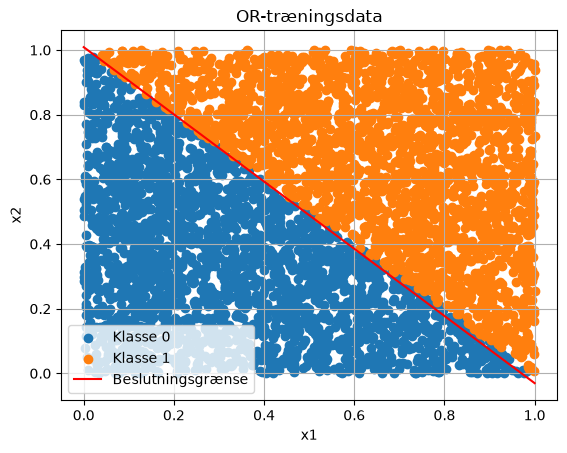

In [123]:
# Tegn datapunkterne med hver sin farve, så klasserne kan skelnes.
for klasse, farve, navn in [
    (0, "tab:blue", "Klasse 0"),
    (1, "tab:orange", "Klasse 1"),
]:
    punkter = [
        inputs for inputs, svar in træningsdata
        if svar == klasse
    ]
    plt.scatter(
        [punkt[0] for punkt in punkter],
        [punkt[1] for punkt in punkter],
        color=farve,
        label=navn,
    )

# Grænsen ligger, hvor vægt * input + bias = 0.
# Løs ligningen for x2 ved to x1-værdier for at tegne linjen.
tærskel = 0.5

x1_værdier = [0, 1]

if perceptron.vægt[1] != 0:
    x2_værdier = [
        (tærskel - perceptron.bias - perceptron.vægt[0] * x1)
        / perceptron.vægt[1]
        for x1 in x1_værdier
    ]
    plt.plot(x1_værdier, x2_værdier, color="red", label="Beslutningsgrænse")


plt.xlabel("x1")
plt.ylabel("x2")
plt.title("OR-træningsdata")
plt.legend()
plt.grid(True)
# Vis grafen i et separat vindue.
plt.show()